Construct the Directed Friendship Network

In [1]:
# import necessary packages
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

In [2]:
# import the self-reported friendship data
df_friendships = pl.read_csv("/Users/maggiebothwell/Documents/GitHub/Project-Repository/Data/Raw/Friendship-network_data_2013.csv", 
    separator=" ",
    has_header=False,
    new_columns=["i", "j"])

print(df_friendships) 

shape: (668, 2)
┌──────┬──────┐
│ i    ┆ j    │
│ ---  ┆ ---  │
│ i64  ┆ i64  │
╞══════╪══════╡
│ 1    ┆ 55   │
│ 1    ┆ 205  │
│ 1    ┆ 272  │
│ 1    ┆ 494  │
│ 1    ┆ 779  │
│ …    ┆ …    │
│ 1519 ┆ 1828 │
│ 1594 ┆ 1519 │
│ 1594 ┆ 1828 │
│ 1828 ┆ 1519 │
│ 1828 ┆ 1594 │
└──────┴──────┘


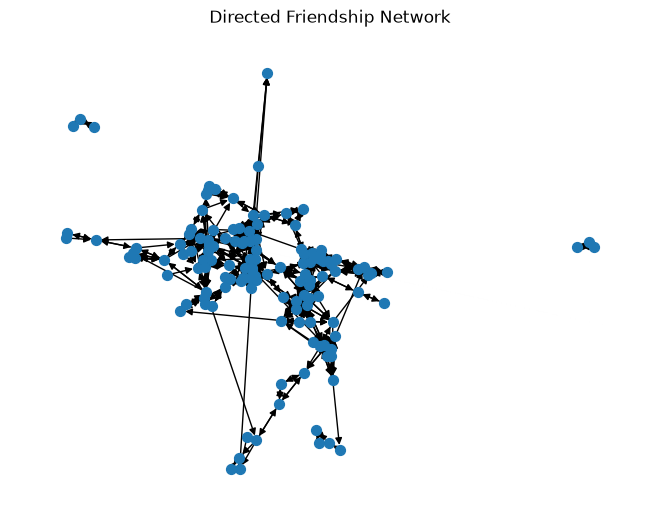

In [3]:
# create a directed network from the friendship data 
G_friendship = nx.from_pandas_edgelist(df_friendships, "i", "j", create_using=nx.DiGraph())

# view the graph and give it a title
nx.draw(G_friendship, node_size =50)
plt.title("Directed Friendship Network")
plt.show()


In [4]:
G_friendship.number_of_nodes()
# G_friendship.number_of_edges()

134

In [ ]:
import pickle
from pathlib import Path

# this code is used to save the friendship networks to a pickle file, which can then be retrieved in another notebook within the repository
save_path = Path("../Data/Cleaned/friendship_network.pkl")

with save_path.open("wb") as file:
    pickle.dump(G_friendship, file)

Construct the Directed Network from the Contact Diary

In [7]:
# import the self-reported friendship data
df_contact_diary = pl.read_csv("/Users/maggiebothwell/Documents/GitHub/Project-Repository/Data/Raw/Contact-diaries-network_data_2013.csv", 
    separator=" ",
    has_header=False,
    new_columns=["i", "j", "w"])

print(df_contact_diary)

shape: (502, 3)
┌──────┬──────┬─────┐
│ i    ┆ j    ┆ w   │
│ ---  ┆ ---  ┆ --- │
│ i64  ┆ i64  ┆ i64 │
╞══════╪══════╪═════╡
│ 3    ┆ 28   ┆ 2   │
│ 3    ┆ 106  ┆ 1   │
│ 3    ┆ 147  ┆ 4   │
│ 3    ┆ 177  ┆ 1   │
│ 3    ┆ 295  ┆ 4   │
│ …    ┆ …    ┆ …   │
│ 1828 ┆ 1237 ┆ 1   │
│ 1828 ┆ 1295 ┆ 1   │
│ 1828 ┆ 1412 ┆ 1   │
│ 1828 ┆ 1423 ┆ 2   │
│ 1828 ┆ 1594 ┆ 4   │
└──────┴──────┴─────┘


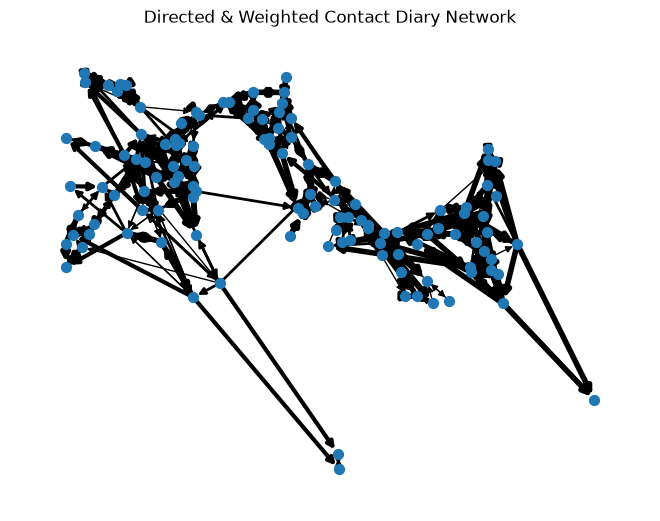

In [8]:
# create a weighted directed network from the contact diary data 
G_contact_diary = nx.from_pandas_edgelist(df_contact_diary, "i", "j", edge_attr="w", create_using=nx.DiGraph())

# view the graph, including edge weights as line widths - thicker edges represent a longer reported time of contact 
nx.draw(G_contact_diary, node_size =50, width=list(nx.get_edge_attributes(G_contact_diary, "w").values()))

plt.title("Directed & Weighted Contact Diary Network")
plt.show()

In [15]:
G_contact_diary.number_of_nodes()


120

In [ ]:
import pickle
from pathlib import Path

# this code is used to save the contact diary networks to a pickle file, which can then be retrieved in another notebook within the repository
save_path = Path("../Data/Cleaned/contact_diary_network.pkl")

with save_path.open("wb") as file:
    pickle.dump(G_contact_diary, file)